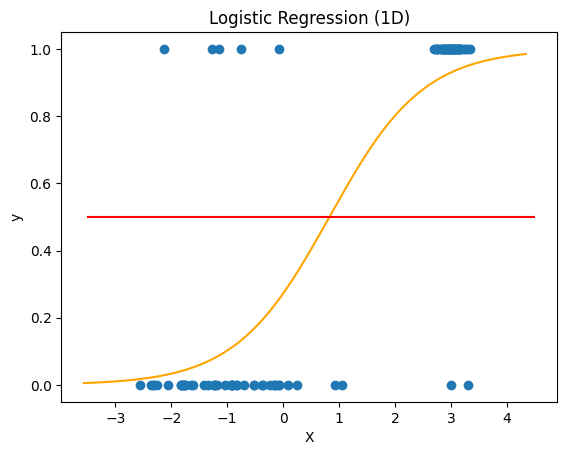

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression

X,y = make_classification(
    n_samples=100,
    n_features=1,
    n_informative=1,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=1,
    weights=[0.5,0.5],
    flip_y=0.15,
    class_sep=2.0,
    hypercube=True,
    shift=1.0,
    scale=1.0,
    shuffle=True,
    random_state=88
)

model = LogisticRegression()
model.fit(X, y)

X_line = np.linspace(X.min() - 1, X.max() + 1, 300).reshape(-1, 1)
y_prob = model.predict_proba(X_line)[:, 1]

plt.scatter(X, y, label="data points")
plt.plot(X_line, y_prob, color="orange", label="sigmoid curve")
plt.hlines(y=0.5, xmin=-3.5, xmax=4.5, color='red', linewidths=1.5)
plt.title("Logistic Regression (1D)")
plt.xlabel("X")
plt.ylabel("y")

plt.show()

In [15]:
def predict_prob(coefs, X):
    a, b = coefs
    return 1 / (1 + np.exp(-(a * X + b)))

In [16]:
coefs = [model.coef_[0][0], model.intercept_[0]]

my_probs = predict_prob(coefs, X)
sk_probs = model.predict_proba(X)[:,1]

print(np.allclose(my_probs, sk_probs))  

False


In [17]:
def predict_class(coefs, X):
    probs = predict_prob(coefs, X)
    return (probs >= 0.5).astype(int)

In [18]:
my_pred = predict_class(coefs, X)
sk_pred = model.predict(X)

print(np.array_equal(my_pred, sk_pred))  

False


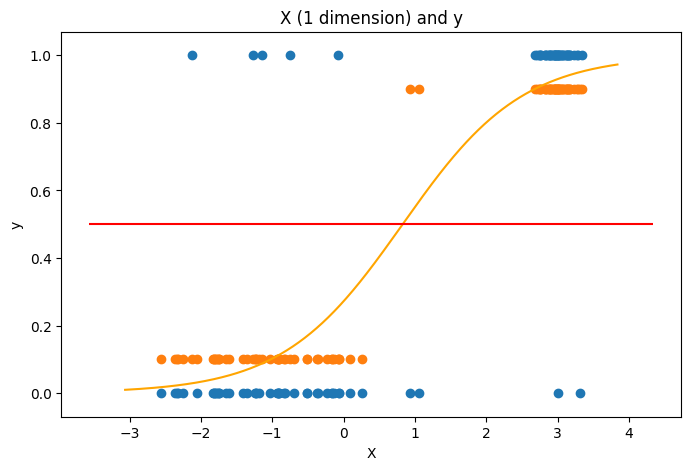

In [ ]:
y_pred = predict_class(coefs, X)

X_line = np.linspace(X.min() - 0.5, X.max() + 0.5, 500).reshape(-1, 1)
y_prob = predict_prob(coefs, X_line)

plt.figure(figsize=(8, 5))

y_plot_offset = np.where(y_pred == 1, 0.9, 0.1)

plt.scatter(X, y, label="real", color="tab:blue")
plt.scatter(X, y_plot_offset, label="predicted", color="tab:orange")

plt.plot(X_line, y_prob, color="orange")
plt.hlines(y=0.5, xmin=X.min()-1, xmax=X.max()+1, color='red')


plt.title("X (1 dimension) and y")
plt.xlabel("X")
plt.ylabel("y")
plt.ylim(-0.07, 1.07)

plt.show()

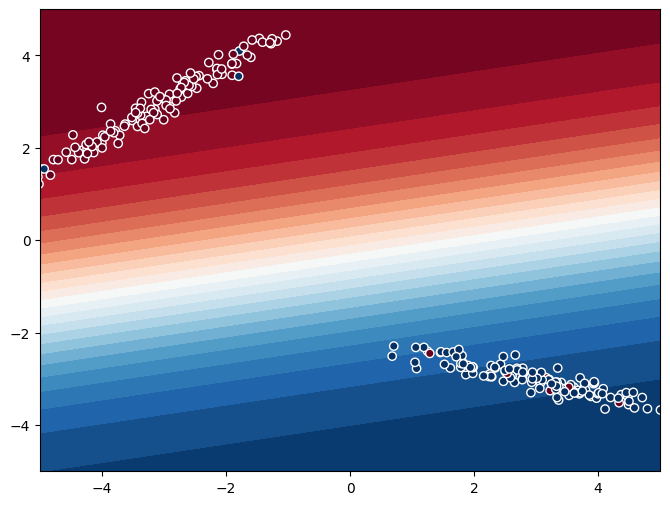

In [32]:
X, y = make_classification(
    n_features=2,
    n_redundant=0,
    n_samples=250,
    n_classes=2,
    n_clusters_per_class=1,
    flip_y=0.05,
    class_sep=3,
    random_state=43
)

clf = LogisticRegression()
clf.fit(X, y)

xx, yy = np.mgrid[-5:5:.01, -5:5:.01]
grid = np.c_[xx.ravel(), yy.ravel()]

probs = clf.predict_proba(grid)[:, 1].reshape(xx.shape)

f, ax = plt.subplots(figsize=(8, 6))

contour = ax.contourf(xx, yy, probs, 25, cmap="RdBu", vmin=0, vmax=1)

ax.scatter(X[:,0], X[:,1], c=y, cmap="RdBu", edgecolor="white")

ax.set(xlim=(-5,5), ylim=(-5,5))
plt.show()